# Analisis Jigsaw Toxic Comment

| | |
|---|---|
| **Sumber** | https://www.kaggle.com/c/jigsaw-toxic-comment-classification-challenge/data |
| **Ditempatkan di kategori** | Klasifikasi Multilabel |
| **Jenis klasifikasi sebenarnya** | Multilabel (6 label biner yang bisa aktif bersamaan) |
| **Status** | ✅ Dataset yang **benar** untuk kategori ini |

## 1. Data Collecting

Dataset ini berasal dari **kompetisi** Kaggle (link di tabel atas).

1. Login Kaggle, buka halaman kompetisi, klik **Join Competition**, lalu download file data.
2. Extract `train.csv` dan taruh di **folder yang sama dengan notebook ini**.
3. File data tidak ikut di-push ke GitHub karena sudah masuk `.gitignore`.

In [1]:
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## 2. Data Loading

In [2]:
DATA_PATH = "train.csv"   # sesuaikan jika nama file berbeda (boleh juga train.csv.zip)
df = pd.read_csv(DATA_PATH)
LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
print("Ukuran data (baris, kolom):", df.shape)
df.head()

Ukuran data (baris, kolom): (159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


## 3. Identifikasi Jenis Klasifikasi

Pada multilabel, satu sampel boleh punya **lebih dari satu label aktif** sekaligus. Kita hitung berapa label aktif per komentar.

In [3]:
jumlah_label_aktif = df[LABELS].sum(axis=1)
print("Jumlah kolom label:", len(LABELS))
print("\nBanyak komentar menurut jumlah label aktif:")
print(jumlah_label_aktif.value_counts().sort_index())
persen = (jumlah_label_aktif > 1).mean() * 100
print(f"\nKomentar dengan lebih dari 1 label aktif: {persen:.2f}%")
assert (jumlah_label_aktif > 1).any()
print("Kesimpulan: satu komentar bisa punya beberapa label sekaligus -> KLASIFIKASI MULTILABEL")

Jumlah kolom label: 6

Banyak komentar menurut jumlah label aktif:
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31
Name: count, dtype: int64

Komentar dengan lebih dari 1 label aktif: 6.18%
Kesimpulan: satu komentar bisa punya beberapa label sekaligus -> KLASIFIKASI MULTILABEL


## 4. Data Cleaning & Transformation

Data besar (±160 ribu komentar), jadi diambil **sampel acak 20.000 baris** agar training cepat.
Label `threat` jarang muncul, jadi hasilnya untuk label itu bisa kurang stabil.

In [4]:
print("Nilai kosong:", df.isna().sum().sum())
df["comment_text"] = df["comment_text"].fillna("")
print("Duplikat teks:", df["comment_text"].duplicated().sum())

SAMPLE = 20000
df = df.sample(n=min(SAMPLE, len(df)), random_state=42).reset_index(drop=True)
print("Ukuran setelah sampling:", df.shape)

Nilai kosong: 0
Duplikat teks: 0
Ukuran setelah sampling: (20000, 8)


## 5. EDA & ExDA

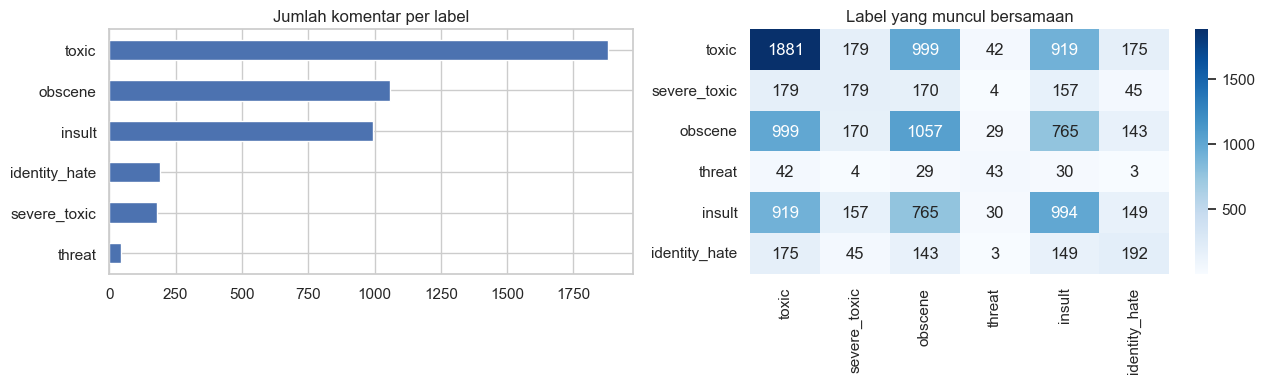

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df[LABELS].sum().sort_values().plot(kind="barh", ax=ax[0])
ax[0].set_title("Jumlah komentar per label")

sns.heatmap(df[LABELS].T.dot(df[LABELS]), annot=True, fmt="d", cmap="Blues", ax=ax[1])
ax[1].set_title("Label yang muncul bersamaan")
plt.tight_layout(); plt.show()

In [6]:
df["panjang"] = df["comment_text"].str.split().str.len()
df.groupby(df["toxic"].map({0: "tidak toxic", 1: "toxic"}))["panjang"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
toxic,,,,,,,,
tidak toxic,18119.0,67.2,95.0,1.0,18.0,38.0,76.0,946.0
toxic,1881.0,48.3,97.2,2.0,11.0,22.0,49.0,1344.0


## 6. Data Processing

Teks diubah menjadi angka dengan **TF-IDF**. Seperti sebelumnya, vectorizer di-fit setelah split (bagian 7).

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

X_text = df["comment_text"]
Y = df[LABELS]

vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 2),
                             stop_words="english", min_df=3, sublinear_tf=True)

## 7. Data Splitting

In [8]:
from sklearn.model_selection import train_test_split

X_train_t, X_test_t, Y_train, Y_test = train_test_split(
    X_text, Y, test_size=0.2, random_state=42, stratify=df["toxic"]
)
X_train_p = vectorizer.fit_transform(X_train_t)
X_test_p = vectorizer.transform(X_test_t)
print("Data latih:", X_train_p.shape, "| Data uji:", X_test_p.shape)

Data latih: (16000, 20000) | Data uji: (4000, 20000)


## 8. Modelling & Evaluasi

Model yang dipakai: Logistic Regression dan Linear SVM (keduanya dibungkus `OneVsRestClassifier`, satu model per label), serta Decision Tree yang mendukung multilabel secara langsung.
Gradient Boosting tidak dipakai karena sangat lambat pada fitur TF-IDF.

In [9]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import hamming_loss, accuracy_score, f1_score, classification_report

models = {
    "Logistic Regression (OvR)": OneVsRestClassifier(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Linear SVM (OvR)": OneVsRestClassifier(LinearSVC(class_weight="balanced")),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, random_state=42),
}

hasil, preds = [], {}
for nama, model in models.items():
    model.fit(X_train_p, Y_train)
    pred = model.predict(X_test_p)
    preds[nama] = pred
    hasil.append({
        "Model": nama,
        "Hamming Loss": hamming_loss(Y_test, pred),
        "Subset Accuracy": accuracy_score(Y_test, pred),
        "F1 micro": f1_score(Y_test, pred, average="micro", zero_division=0),
        "F1 macro": f1_score(Y_test, pred, average="macro", zero_division=0),
        "F1 samples": f1_score(Y_test, pred, average="samples", zero_division=0),
    })

tabel = pd.DataFrame(hasil).set_index("Model").round(4)
tabel

,Hamming Loss,Subset Accuracy,F1 micro,F1 macro,F1 samples
Model,,,,,
Logistic Regression (OvR),0.0282,0.8858,0.6505,0.4811,0.0575
Linear SVM (OvR),0.0248,0.8972,0.6590,0.4756,0.0566
Decision Tree,0.0228,0.9132,0.6133,0.3840,0.0395


In [10]:
terbaik = tabel["F1 macro"].idxmax()
print("Model terbaik berdasarkan F1 macro:", terbaik, "\n")
print(classification_report(Y_test, preds[terbaik], target_names=LABELS, zero_division=0))

Model terbaik berdasarkan F1 macro: Logistic Regression (OvR) 

               precision    recall  f1-score   support

        toxic       0.66      0.75      0.70       376
 severe_toxic       0.19      0.55      0.28        29
      obscene       0.72      0.83      0.77       208
       threat       0.25      0.18      0.21        11
       insult       0.58      0.72      0.64       195
identity_hate       0.20      0.44      0.28        36

    micro avg       0.58      0.74      0.65       855
    macro avg       0.43      0.58      0.48       855
 weighted avg       0.62      0.74      0.67       855
  samples avg       0.06      0.07      0.06       855



## 9. Kesimpulan

**Kenapa dataset ini multilabel.** Dataset punya 6 kolom label biner (`toxic`, `severe_toxic`, `obscene`, `threat`, `insult`, `identity_hate`) yang bisa aktif bersamaan. Pada data lengkap (159.571 komentar), 6,18% komentar punya lebih dari satu label aktif, dan 31 komentar aktif di keenam label sekaligus. Heatmap juga menunjukkan label sering muncul berpasangan, misalnya `toxic` dengan `obscene` (999 komentar) dan `toxic` dengan `insult` (919 komentar) pada sampel 20.000 baris. Pada klasifikasi multikelas, satu baris hanya boleh punya satu kelas, jadi dataset ini tidak termasuk multikelas.

**Hasil model** (data uji 4.000 komentar):

| Model | Hamming Loss | Subset Accuracy | F1 micro | F1 macro |
|---|---|---|---|---|
| Logistic Regression (OvR) | 0,0282 | 0,8858 | 0,6505 | **0,4811** |
| Linear SVM (OvR) | 0,0248 | 0,8972 | **0,6590** | 0,4756 |
| Decision Tree | **0,0228** | **0,9132** | 0,6133 | 0,3840 |

**Model terbaik.** Logistic Regression dipilih karena F1 macro tertinggi (0,4811). Metrik ini memperlakukan keenam label setara, termasuk label yang jarang muncul. Linear SVM unggul tipis di F1 micro (0,6590) dan selisih F1 macro-nya kecil. Decision Tree tampak terbaik di Hamming Loss dan Subset Accuracy, tetapi F1 macro-nya paling rendah (0,3840). Angka itu menipu karena sekitar 90% komentar tidak punya label sama sekali, sehingga model yang cenderung menebak "tidak ada label" otomatis terlihat bagus. Sebagai pembanding, model yang selalu menebak nol sudah mendapat Hamming Loss sekitar 0,0356 dan Subset Accuracy sekitar 0,90.

**Label yang paling sulit ditebak** (Logistic Regression, F1 per label):
- `threat` (0,21), `severe_toxic` (0,28), dan `identity_hate` (0,28) paling sulit. Contohnya sedikit (data uji hanya berisi 11 komentar `threat`), dan precision-nya rendah (0,19 sampai 0,25).
- `obscene` (0,77), `toxic` (0,70), dan `insult` (0,64) paling mudah karena contohnya banyak dan sering memakai kata-kata khas.

**Catatan.** Nilai F1 samples yang rendah (0,04 sampai 0,06) tidak berarti model buruk. Komentar tanpa label dihitung nol pada rata-rata ini, dan jumlahnya mayoritas. Karena itu F1 micro dan F1 macro lebih tepat untuk menilai model. Analisis ini memakai sampel acak 20.000 dari 159.571 komentar, sehingga hasil label langka bisa berubah jika memakai data penuh atau menyetel threshold prediksi.